<a href="https://colab.research.google.com/github/milaazizah/AnalisisProject_Tahap3_Kelompok02_3TIB/blob/main/AnalisisProject_Tahap3_Kelompok02_3TIB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

FILE_PATH = "3TIB_02_KatalogGempaIndonesiaTimur.xlsx"
OUT_DIR = "/content/hasil_analisis"
os.makedirs(OUT_DIR, exist_ok=True)
ALPHA = 0.05


def judul(teks):
    print("\n" + "=" * 78 + f"\n{teks}\n" + "=" * 78)


def simpan(nama):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, nama), dpi=150)
    plt.show()

judul("PERSIAPAN DATA")
df = pd.read_excel(FILE_PATH)
df.columns = ["No", "Tanggal", "Waktu_UTC", "Lintang", "Bujur", "Kedalaman", "Magnitudo"]
df["Tanggal"] = pd.to_datetime(df["Tanggal"])
df["Tahun"] = df["Tanggal"].dt.year
df["Bulan"] = df["Tanggal"].dt.to_period("M")

print(f"Jumlah baris          : {len(df):,}")
print(f"Periode               : {df['Tanggal'].min().date()} s.d. {df['Tanggal'].max().date()}")
print(f"Missing value         : {int(df.isna().sum().sum())}")
print(f"Baris duplikat        : {int(df.duplicated().sum())}")
print(f"Kedalaman <= 0 km     : {int((df['Kedalaman'] <= 0).sum())}")

mag = df["Magnitudo"].values
dep = df["Kedalaman"].values


PERSIAPAN DATA
Jumlah baris          : 24,485
Periode               : 2009-04-15 s.d. 2018-11-22
Missing value         : 0
Baris duplikat        : 0
Kedalaman <= 0 km     : 0


## 1. STATISTIKA DESKRIPTIF


1. STATISTIKA DESKRIPTIF
                        Magnitudo (Mw)  Kedalaman (km)
N                           24485.0000      24485.0000
Mean                            4.2126         72.1847
Median                          4.1229         32.0230
Modus (pembulatan 0,1)          3.8000          8.1000
Std Dev                         0.6072         98.3598
Varians                         0.3687       9674.6597
Minimum                         3.0000          3.0200
Q1                              3.6806         10.9200
Q3                              4.6282         99.9540
Maksimum                        7.5000        714.6130
Range                           4.5000        711.5930
IQR                             0.9476         89.0340
Koef. Variasi (%)              14.4143        136.2613
Skewness                        0.4751          2.8364
Kurtosis (excess)              -0.0492          9.9254

Persentil:
     Magnitudo  Kedalaman
P1       3.200      5.558
P5       3.382      6.903
P10 

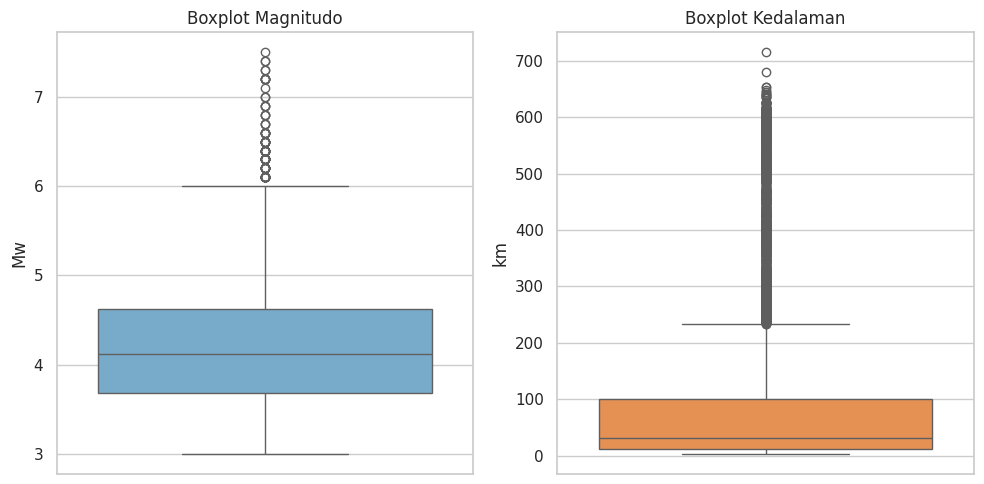

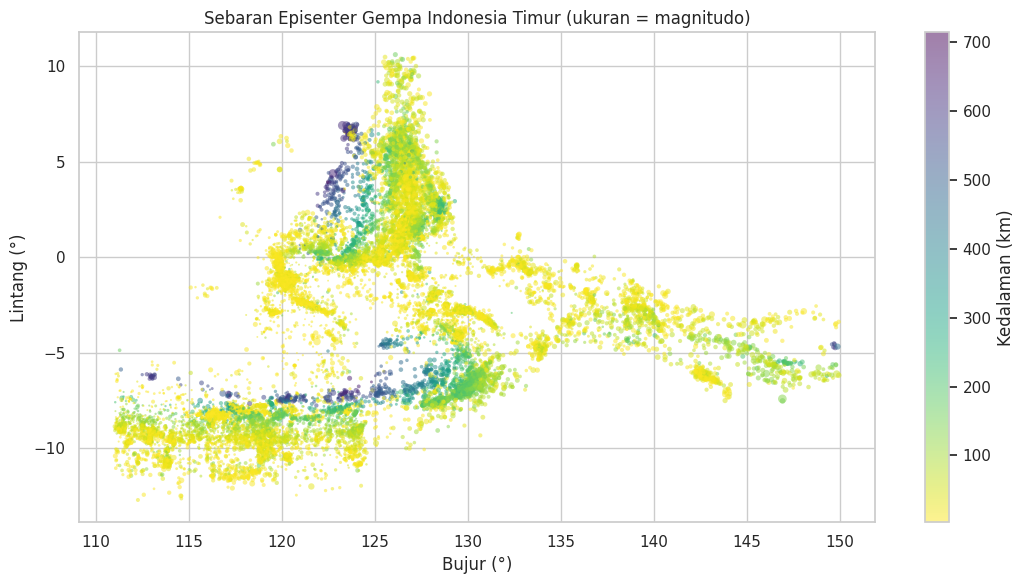

In [4]:
def deskriptif(x):
    q1, q2, q3 = np.percentile(x, [25, 50, 75])
    modus_val = stats.mode(np.round(x, 1), keepdims=False).mode
    return pd.Series({
        "N": len(x), "Mean": x.mean(), "Median": q2, "Modus (pembulatan 0,1)": modus_val,
        "Std Dev": x.std(ddof=1), "Varians": x.var(ddof=1), "Minimum": x.min(), "Q1": q1,
        "Q3": q3, "Maksimum": x.max(), "Range": x.max() - x.min(), "IQR": q3 - q1,
        "Koef. Variasi (%)": x.std(ddof=1) / x.mean() * 100,
        "Skewness": stats.skew(x), "Kurtosis (excess)": stats.kurtosis(x),
    })


tabel_desk = pd.DataFrame({"Magnitudo (Mw)": deskriptif(mag), "Kedalaman (km)": deskriptif(dep)})
print(tabel_desk.round(4).to_string())
tabel_desk.round(4).to_csv(os.path.join(OUT_DIR, "01_statistika_deskriptif.csv"))

# Persentil tambahan
pers = [1, 5, 10, 25, 50, 75, 90, 95, 99]
print("\nPersentil:")
print(pd.DataFrame({"Magnitudo": np.percentile(mag, pers),
                    "Kedalaman": np.percentile(dep, pers)}, index=[f"P{p}" for p in pers]).round(3))

# Klasifikasi kedalaman (BMKG) dan magnitudo
df["Kelas_Kedalaman"] = pd.cut(df["Kedalaman"], [-np.inf, 60, 300, np.inf],
                               labels=["Dangkal (<60)", "Menengah (60-300)", "Dalam (>300)"])
df["Kelas_Kedalaman70"] = np.where(df["Kedalaman"] < 70, "Dangkal (<70 km)", "Non-dangkal (>=70 km)")
df["Kelas_Magnitudo"] = pd.cut(df["Magnitudo"], [0, 4, 5, 6, 7, 10], right=False,
                               labels=["<4", "4-4,9", "5-5,9", "6-6,9", ">=7"])
print("\nFrekuensi kelas kedalaman (BMKG):")
print(df["Kelas_Kedalaman"].value_counts().sort_index())
print("\nFrekuensi kelas magnitudo:")
print(df["Kelas_Magnitudo"].value_counts().sort_index())

# Boxplot
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
sns.boxplot(y=mag, ax=ax[0], color="#6baed6"); ax[0].set_title("Boxplot Magnitudo"); ax[0].set_ylabel("Mw")
sns.boxplot(y=dep, ax=ax[1], color="#fd8d3c"); ax[1].set_title("Boxplot Kedalaman"); ax[1].set_ylabel("km")
simpan("01_boxplot.png")

# Peta sebaran episenter
fig, ax = plt.subplots(figsize=(11, 6))
sc = ax.scatter(df["Bujur"], df["Lintang"], c=df["Kedalaman"], s=(df["Magnitudo"] - 2) ** 2.2,
                cmap="viridis_r", alpha=0.5, edgecolor="none")
plt.colorbar(sc, label="Kedalaman (km)")
ax.set_xlabel("Bujur (°)"); ax.set_ylabel("Lintang (°)")
ax.set_title("Sebaran Episenter Gempa Indonesia Timur (ukuran = magnitudo)")
simpan("01_peta_episenter.png")

### 2(a). POLA SEBARAN DAN FITTING DISTRIBUSI


2. POLA SEBARAN DAN FITTING DISTRIBUSI


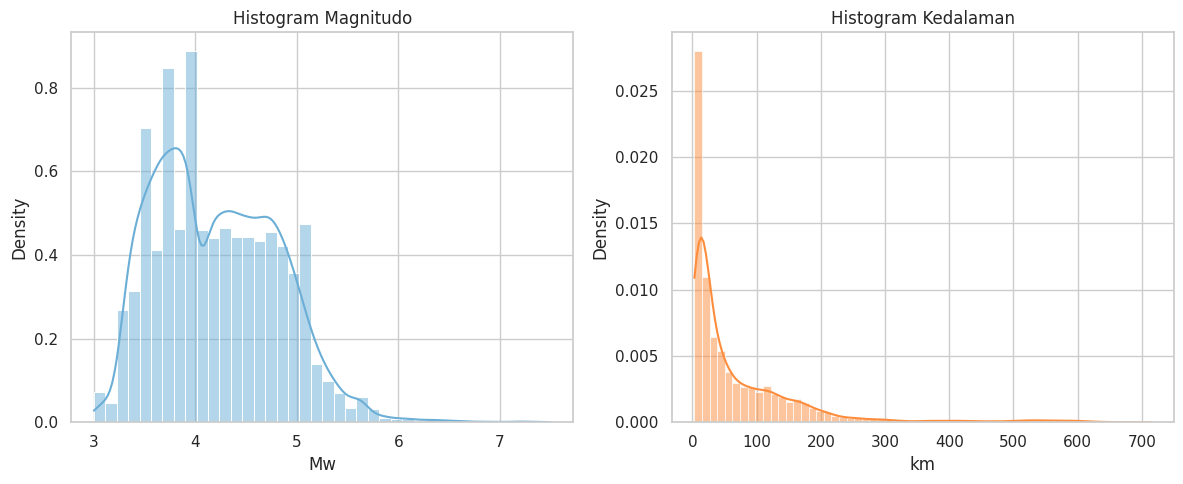

Uji normalitas (H0: data berdistribusi normal)
  Magnitudo  KS D=0.0970 (p=4.28e-201) | D'Agostino K2=835.8 (p=3.25e-182) -> Tolak H0 (tidak normal)
  Kedalaman  KS D=0.2421 (p=0) | D'Agostino K2=14687.3 (p=0) -> Tolak H0 (tidak normal)

Perbandingan distribusi - MAGNITUDO (urut AIC terkecil = terbaik)
         Distribusi  k      LogLik         AIC         BIC   KS_D  KS_p       dAIC
          Lognormal  2 -21958.3805  43920.7609  43936.9726 0.0770   0.0     0.0000
              Gamma  2 -22081.3055  44166.6110  44182.8227 0.0836   0.0   245.8501
             Normal  2 -22527.1924  45058.3849  45074.5965 0.0970   0.0  1137.6240
Log-logistik (Fisk)  2 -22728.7451  45461.4902  45477.7018 0.0791   0.0  1540.7293
            Weibull  2 -24112.4788  48228.9576  48245.1692 0.0980   0.0  4308.1967
           Rayleigh  1 -43477.4603  86956.9206  86965.0264 0.4385   0.0 43036.1597
       Eksponensial  1 -59696.2152 119394.4303 119402.5361 0.5298   0.0 75473.6694

Perbandingan distribusi - KEDAL

In [5]:
# Histogram + KDE
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(mag, bins=40, kde=True, stat="density", ax=ax[0], color="#6baed6")
ax[0].set_title("Histogram Magnitudo"); ax[0].set_xlabel("Mw")
sns.histplot(dep, bins=60, kde=True, stat="density", ax=ax[1], color="#fd8d3c")
ax[1].set_title("Histogram Kedalaman"); ax[1].set_xlabel("km")
simpan("02_histogram.png")

# Uji normalitas
print("Uji normalitas (H0: data berdistribusi normal)")
for nama, x in [("Magnitudo", mag), ("Kedalaman", dep)]:
    ks = stats.kstest((x - x.mean()) / x.std(ddof=1), "norm")
    dag = stats.normaltest(x)
    print(f"  {nama:10s} KS D={ks.statistic:.4f} (p={ks.pvalue:.3g}) | "
          f"D'Agostino K2={dag.statistic:.1f} (p={dag.pvalue:.3g}) -> "
          f"{'Tolak H0 (tidak normal)' if ks.pvalue < ALPHA else 'Gagal tolak H0'}")


def fit_kandidat(x, kandidat, nama_var):
    """Fit sejumlah distribusi dengan MLE, hitung AIC/BIC/KS."""
    hasil, params = [], {}
    n = len(x)
    for nm, dist, kw in kandidat:
        try:
            p = dist.fit(x, **kw)
            ll = np.sum(dist.logpdf(x, *p))
            k = len(p) - len(kw)  # parameter yang diestimasi (bukan yang di-fix)
            ks = stats.kstest(x, dist.cdf, args=p)
            hasil.append({"Distribusi": nm, "k": k, "LogLik": ll, "AIC": 2 * k - 2 * ll,
                          "BIC": k * np.log(n) - 2 * ll, "KS_D": ks.statistic, "KS_p": ks.pvalue})
            params[nm] = (dist, p)
        except Exception as e:
            print(f"  gagal fit {nm}: {e}")
    t = pd.DataFrame(hasil).sort_values("AIC").reset_index(drop=True)
    t["dAIC"] = t["AIC"] - t["AIC"].min()
    print(f"\nPerbandingan distribusi - {nama_var} (urut AIC terkecil = terbaik)")
    print(t.round(4).to_string(index=False))
    return t, params


kand = [
    ("Normal", stats.norm, {}),
    ("Lognormal", stats.lognorm, {"floc": 0}),
    ("Gamma", stats.gamma, {"floc": 0}),
    ("Weibull", stats.weibull_min, {"floc": 0}),
    ("Eksponensial", stats.expon, {"floc": 0}),
    ("Log-logistik (Fisk)", stats.fisk, {"floc": 0}),
    ("Rayleigh", stats.rayleigh, {"floc": 0}),
]
t_mag, p_mag = fit_kandidat(mag, kand, "MAGNITUDO")
t_dep, p_dep = fit_kandidat(dep, kand, "KEDALAMAN")
t_mag.round(4).to_csv(os.path.join(OUT_DIR, "02_fit_distribusi_magnitudo.csv"), index=False)
t_dep.round(4).to_csv(os.path.join(OUT_DIR, "02_fit_distribusi_kedalaman.csv"), index=False)

### 2(b). HUKUM GUTENBERG-RICHTER (magnitudo)


2b. HUKUM GUTENBERG-RICHTER (magnitudo)
Mc (max curvature)          : 3.95  -> Mc terkoreksi = 4.15
N gempa Mw >= Mc            : 12,175
Nilai-b (Aki-Utsu)          : 0.750 +/- 0.007
Interpretasi: b ~ 1 normal untuk wilayah tektonik aktif.
KS terhadap Eksponensial(loc=Mc) : D=0.1716, p=4.14e-314


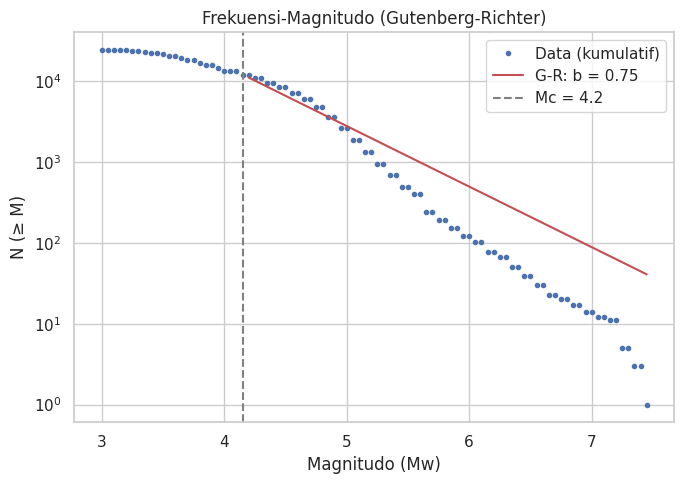

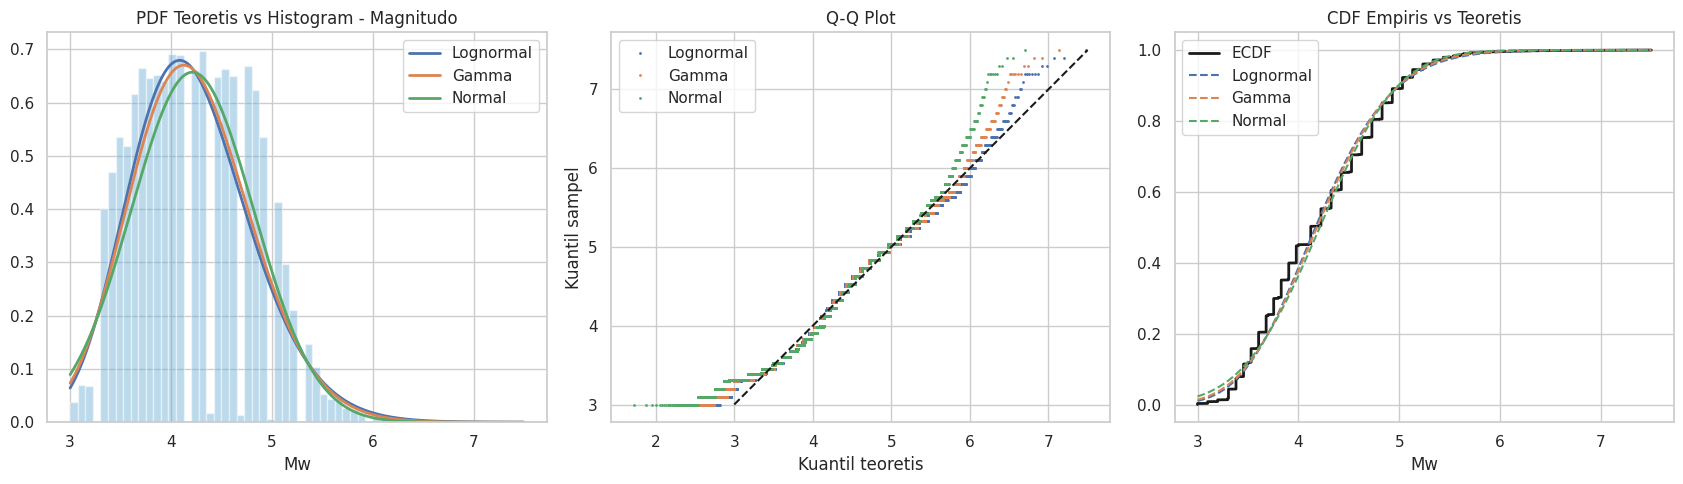

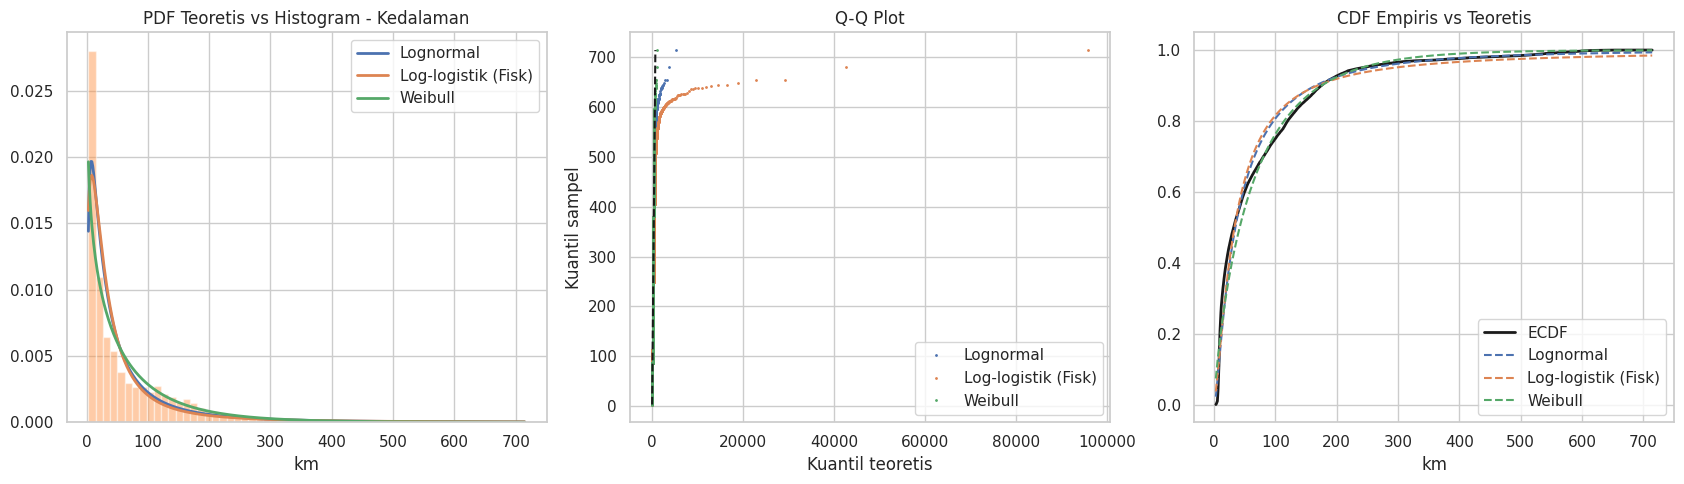

In [6]:
judul("2b. HUKUM GUTENBERG-RICHTER (magnitudo)")
hist_m, edges = np.histogram(mag, bins=np.arange(np.floor(mag.min() * 10) / 10, mag.max() + 0.1, 0.1))
mid = (edges[:-1] + edges[1:]) / 2
Mc = mid[np.argmax(hist_m)]
Mc_koreksi = Mc + 0.2
sub = mag[mag >= Mc_koreksi]
dM = 0.01
b = np.log10(np.e) / (sub.mean() - (Mc_koreksi - dM / 2))
b_se = b / np.sqrt(len(sub))
print(f"Mc (max curvature)          : {Mc:.2f}  -> Mc terkoreksi = {Mc_koreksi:.2f}")
print(f"N gempa Mw >= Mc            : {len(sub):,}")
print(f"Nilai-b (Aki-Utsu)          : {b:.3f} +/- {b_se:.3f}")
print("Interpretasi: b ~ 1 normal untuk wilayah tektonik aktif.")

beta = b * np.log(10)
ks_gr = stats.kstest(sub, "expon", args=(Mc_koreksi, 1 / beta))
print(f"KS terhadap Eksponensial(loc=Mc) : D={ks_gr.statistic:.4f}, p={ks_gr.pvalue:.3g}")

fig, ax = plt.subplots(figsize=(7, 5))
mg = np.arange(mag.min(), mag.max(), 0.05)
Nkum = np.array([(mag >= m).sum() for m in mg])
ax.semilogy(mg, Nkum, "o", ms=3, label="Data (kumulatif)")
mgfit = mg[mg >= Mc_koreksi]
ax.semilogy(mgfit, len(sub) * 10 ** (-b * (mgfit - Mc_koreksi)), "r-", label=f"G-R: b = {b:.2f}")
ax.axvline(Mc_koreksi, ls="--", c="gray", label=f"Mc = {Mc_koreksi:.1f}")
ax.set_xlabel("Magnitudo (Mw)"); ax.set_ylabel("N (≥ M)"); ax.legend(); ax.set_title("Frekuensi-Magnitudo (Gutenberg-Richter)")
simpan("02_gutenberg_richter.png")


def plot_fit(x, tabel, params, nama, fname, warna, xlabel):
    top = tabel["Distribusi"].head(3).tolist()
    fig, ax = plt.subplots(1, 3, figsize=(17, 5))
    ax[0].hist(x, bins=60, density=True, alpha=0.45, color=warna)
    xs = np.linspace(x.min(), x.max(), 500)
    for nm in top:
        d, p = params[nm]
        ax[0].plot(xs, d.pdf(xs, *p), lw=2, label=nm)
    ax[0].set_title(f"PDF Teoretis vs Histogram - {nama}"); ax[0].set_xlabel(xlabel); ax[0].legend()
    # Q-Q
    probs = (np.arange(1, len(x) + 1) - 0.5) / len(x)
    xs_sorted = np.sort(x)
    for nm in top:
        d, p = params[nm]
        ax[1].plot(d.ppf(probs, *p), xs_sorted, ".", ms=2, label=nm)
    lim = [x.min(), x.max()]
    ax[1].plot(lim, lim, "k--"); ax[1].set_title("Q-Q Plot"); ax[1].set_xlabel("Kuantil teoretis"); ax[1].set_ylabel("Kuantil sampel"); ax[1].legend()
    # CDF empiris vs teoretis
    ax[2].plot(xs_sorted, probs, "k", lw=2, label="ECDF")
    for nm in top:
        d, p = params[nm]
        ax[2].plot(xs, d.cdf(xs, *p), "--", label=nm)
    ax[2].set_title("CDF Empiris vs Teoretis"); ax[2].set_xlabel(xlabel); ax[2].legend()
    simpan(fname)


plot_fit(mag, t_mag, p_mag, "Magnitudo", "02_fit_magnitudo.png", "#6baed6", "Mw")
plot_fit(dep, t_dep, p_dep, "Kedalaman", "02_fit_kedalaman.png", "#fd8d3c", "km")

### 2(c). KEDALAMAN: CAMPURAN DISTRIBUSI LOG-NORMAL


2c. KEDALAMAN: CAMPURAN DISTRIBUSI LOG-NORMAL
 Komponen  AIC_skala_asli
        1        253032.5
        2        246942.0
        3        246441.0
        4        246081.5

Jumlah komponen terbaik (AIC): 4
  Komponen: bobot=0.351, median=9.4 km, sigma(log)=0.316
  Komponen: bobot=0.265, median=29.7 km, sigma(log)=0.443
  Komponen: bobot=0.244, median=98.9 km, sigma(log)=0.434
  Komponen: bobot=0.140, median=200.9 km, sigma(log)=0.592


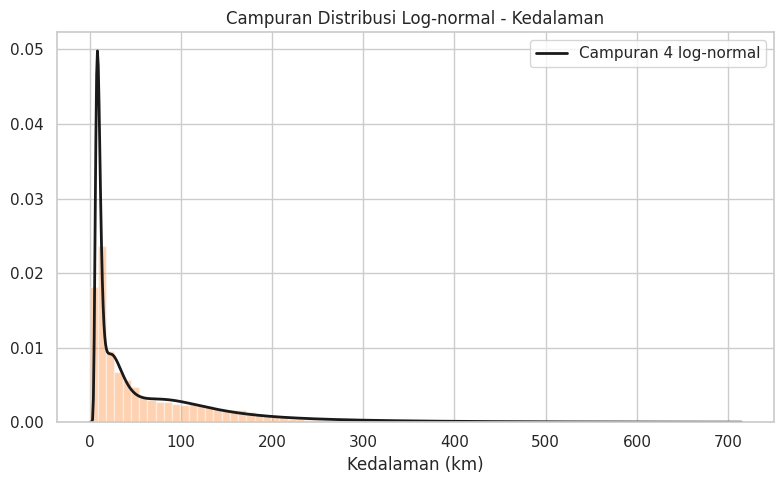

In [8]:
judul("2c. KEDALAMAN: CAMPURAN DISTRIBUSI LOG-NORMAL")
try:
    from sklearn.mixture import GaussianMixture
    lx = np.log(dep).reshape(-1, 1)
    gm_tab = []
    for k in [1, 2, 3, 4]:
        gm = GaussianMixture(k, n_init=5, random_state=42).fit(lx)
        ll_asli = gm.score(lx) * len(lx) - np.sum(lx)
        gm_tab.append({"Komponen": k, "AIC_skala_asli": 2 * (3 * k - 1) - 2 * ll_asli})
    print(pd.DataFrame(gm_tab).round(1).to_string(index=False))
    kbest = min(gm_tab, key=lambda r: r["AIC_skala_asli"])["Komponen"]
    gm = GaussianMixture(kbest, n_init=5, random_state=42).fit(lx)
    print(f"\nJumlah komponen terbaik (AIC): {kbest}")
    for i in np.argsort(gm.means_.ravel()):
        print(f"  Komponen: bobot={gm.weights_[i]:.3f}, median={np.exp(gm.means_[i, 0]):.1f} km, "
              f"sigma(log)={np.sqrt(gm.covariances_[i, 0, 0]):.3f}")
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(dep, bins=np.linspace(0, dep.max(), 80), density=True, alpha=0.4, color="#fd8d3c")
    xs = np.linspace(0.5, dep.max(), 800)
    pdf = np.exp(gm.score_samples(np.log(xs).reshape(-1, 1))) / xs
    ax.plot(xs, pdf, "k", lw=2, label=f"Campuran {kbest} log-normal")
    ax.set_xlabel("Kedalaman (km)"); ax.legend(); ax.set_title("Campuran Distribusi Log-normal - Kedalaman")
    simpan("02_campuran_kedalaman.png")
except ImportError:
    print("scikit-learn tidak terpasang; bagian campuran dilewati (pip install scikit-learn).")

## 3. JUMLAH KEJADIAN PER PERIODE DAN DISTRIBUSI POISSON

Jumlah gempa per tahun (2009 dan 2018 data parsial):
Tahun
2009     897
2010    2229
2011    1608
2012    2811
2013    1838
2014    2299
2015    2438
2016    2534
2017    3149
2018    4682


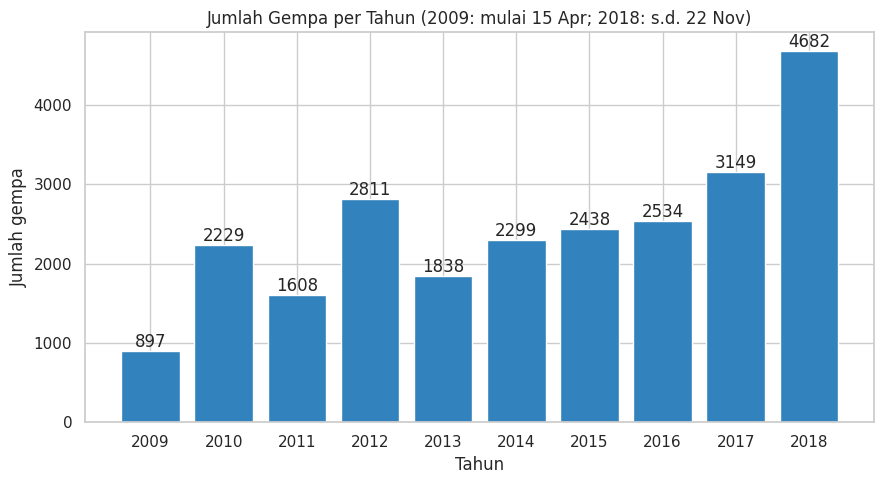

In [9]:
per_tahun = df.groupby("Tahun").size()
print("Jumlah gempa per tahun (2009 dan 2018 data parsial):")
print(per_tahun.to_string())
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(per_tahun.index.astype(str), per_tahun.values, color="#3182bd")
ax.bar_label(bars)
ax.set_title("Jumlah Gempa per Tahun (2009: mulai 15 Apr; 2018: s.d. 22 Nov)")
ax.set_xlabel("Tahun"); ax.set_ylabel("Jumlah gempa")
simpan("03_gempa_per_tahun.png")


Bulan penuh dianalisis: 114 bulan (Mei 2009 - Okt 2018)
count    114.000
mean     210.491
std      112.136
min       38.000
25%      147.250
50%      187.500
75%      239.750
max      933.000
dtype: float64


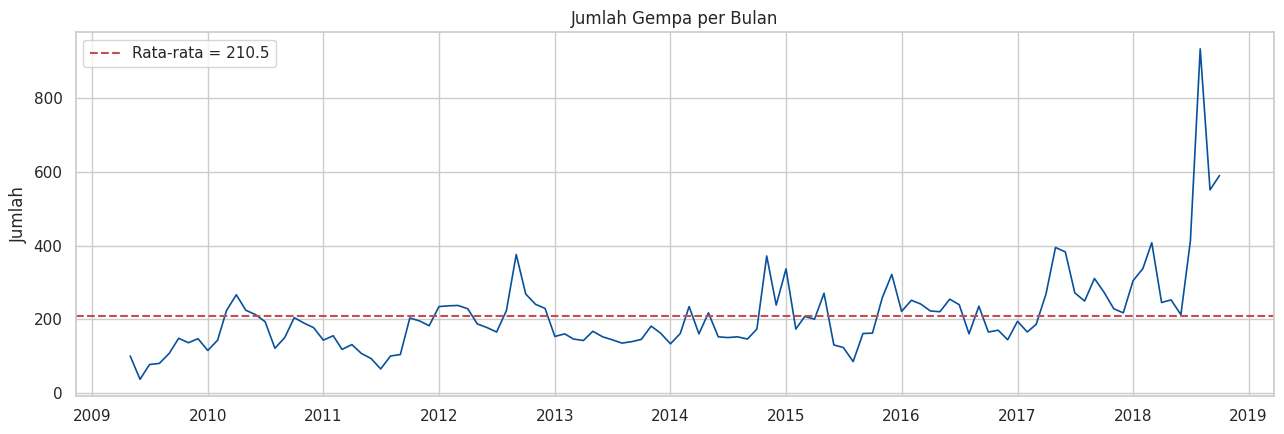


Uji keseragaman antar bulan kalender: chi2=228.0, p=1.1e-42

--- Jumlah gempa per BULAN ---
n=114, lambda(mean)=210.491, varians=12574.518, indeks dispersi=59.739
Uji dispersi: chi2=6750.5, p=0 -> overdispersi/underdispersi (BUKAN Poisson)
Chi-square GOF Poisson: chi2=691.58, df=17, p=5.36e-136

--- Jumlah gempa per TAHUN (2010-2017, tahun penuh) ---
n=8, lambda(mean)=2363.250, varians=245866.786, indeks dispersi=104.038
Uji dispersi: chi2=728.3, p=1.11e-152 -> overdispersi/underdispersi (BUKAN Poisson)
Chi-square GOF tidak dihitung (sampel terlalu sedikit untuk df > 0); gunakan uji dispersi.

--- Jumlah gempa per HARI (16 Apr 2009 - 21 Nov 2018) ---
n=3507, lambda(mean)=6.975, varians=46.078, indeks dispersi=6.606
Uji dispersi: chi2=23161.3, p=0 -> overdispersi/underdispersi (BUKAN Poisson)
Chi-square GOF Poisson: chi2=5894.24, df=14, p=0


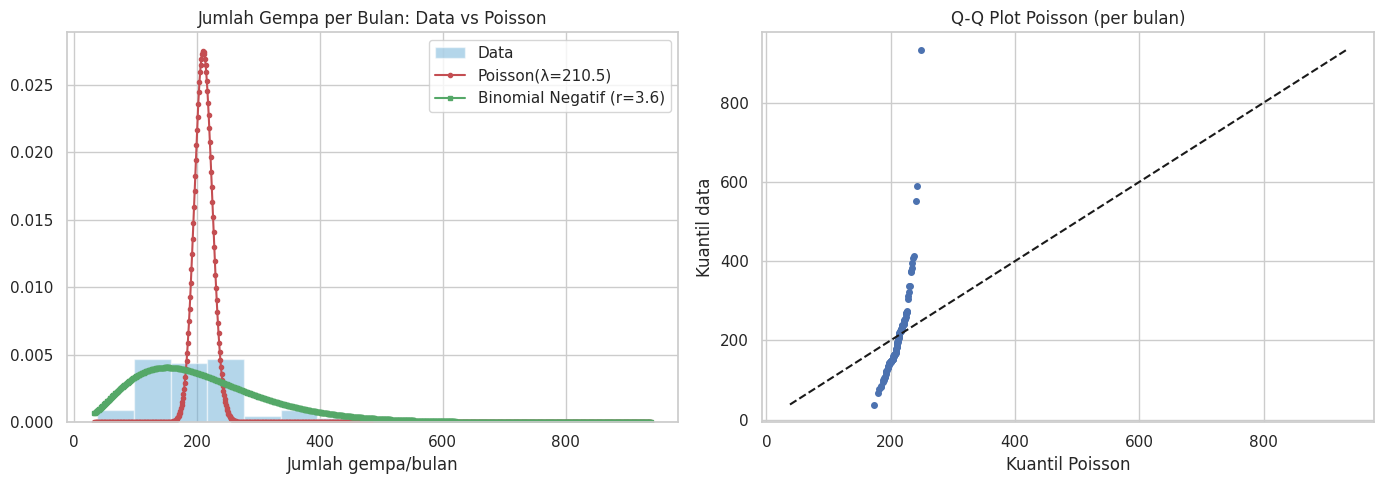

In [10]:
# 3b. Per bulan (hanya bulan penuh: Mei 2009 - Okt 2018)
per_bulan_all = df.groupby("Bulan").size()
per_bulan = per_bulan_all.loc[pd.Period("2009-05"):pd.Period("2018-10")]
per_bulan = per_bulan.reindex(pd.period_range("2009-05", "2018-10", freq="M"), fill_value=0)
print(f"\nBulan penuh dianalisis: {len(per_bulan)} bulan (Mei 2009 - Okt 2018)")
print(per_bulan.describe().round(3))

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(per_bulan.index.to_timestamp(), per_bulan.values, lw=1.2, color="#08519c")
ax.axhline(per_bulan.mean(), color="r", ls="--", label=f"Rata-rata = {per_bulan.mean():.1f}")
ax.set_title("Jumlah Gempa per Bulan"); ax.set_ylabel("Jumlah"); ax.legend()
simpan("03_gempa_per_bulan.png")

# Pola musiman (bulan kalender)
musim = df[(df["Tanggal"] >= "2009-05-01") & (df["Tanggal"] <= "2018-10-31")].groupby(df["Tanggal"].dt.month).size()
chi_musim = stats.chisquare(musim.values)
print(f"\nUji keseragaman antar bulan kalender: chi2={chi_musim.statistic:.1f}, p={chi_musim.pvalue:.3g}")


def uji_poisson(counts, label, binning_min_exp=5):
    """Uji kecocokan Poisson: indeks dispersi + chi-square goodness-of-fit."""
    counts = np.asarray(counts)
    n, lam, var = len(counts), counts.mean(), counts.var(ddof=1)
    D = var / lam
    chi_disp = (n - 1) * D  # statistik dispersi ~ chi2(n-1) di bawah H0 Poisson
    p_disp = 2 * min(stats.chi2.cdf(chi_disp, n - 1), stats.chi2.sf(chi_disp, n - 1))
    print(f"\n--- {label} ---")
    print(f"n={n}, lambda(mean)={lam:.3f}, varians={var:.3f}, indeks dispersi={D:.3f}")
    print(f"Uji dispersi: chi2={chi_disp:.1f}, p={p_disp:.3g} -> "
          f"{'overdispersi/underdispersi (BUKAN Poisson)' if p_disp < ALPHA else 'konsisten dengan Poisson'}")
    # chi-square GOF dengan penggabungan kelas
    kmax = int(counts.max())
    obs_full = np.array([(counts == k).sum() for k in range(kmax + 1)], dtype=float)
    exp_full = n * stats.poisson.pmf(np.arange(kmax + 1), lam)
    exp_full[-1] += n * stats.poisson.sf(kmax, lam)  # ekor
    # penggabungan kelas dengan expected < 5 (gabung dari kiri-kanan menjadi bin lebar)
    bin_o, bin_e, so, se = [], [], 0, 0
    for o, e in zip(obs_full, exp_full):
        so += o; se += e
        if se >= binning_min_exp:
            bin_o.append(so); bin_e.append(se); so = se = 0
    if se > 0 and bin_e:
        bin_o[-1] += so; bin_e[-1] += se
    bin_o, bin_e = np.array(bin_o), np.array(bin_e)
    chi = ((bin_o - bin_e) ** 2 / bin_e).sum()
    dfree = len(bin_o) - 1 - 1
    pval = stats.chi2.sf(chi, dfree) if dfree > 0 else np.nan
    if dfree > 0:
        print(f"Chi-square GOF Poisson: chi2={chi:.2f}, df={dfree}, p={pval:.3g}")
    else:
        print("Chi-square GOF tidak dihitung (sampel terlalu sedikit untuk df > 0); gunakan uji dispersi.")
    return lam, var, D, p_disp, chi, dfree, pval


res_bulan = uji_poisson(per_bulan.values, "Jumlah gempa per BULAN")
res_tahun = uji_poisson(per_tahun.loc[2010:2017].values, "Jumlah gempa per TAHUN (2010-2017, tahun penuh)")

# Per hari & per minggu (lebih banyak sampel -> uji lebih bermakna)
rentang_hari = pd.date_range("2009-04-16", "2018-11-21", freq="D")
per_hari = df.groupby("Tanggal").size().reindex(rentang_hari, fill_value=0)
res_hari = uji_poisson(per_hari.values, "Jumlah gempa per HARI (16 Apr 2009 - 21 Nov 2018)")

# Visual: histogram frekuensi bulanan vs pmf Poisson & Binomial Negatif
lam, var = per_bulan.mean(), per_bulan.var(ddof=1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ks_ = np.arange(int(per_bulan.min()) - 5, int(per_bulan.max()) + 6)
ks_ = ks_[ks_ >= 0]
ax[0].hist(per_bulan.values, bins=15, density=True, alpha=0.5, color="#6baed6", label="Data")
ax[0].plot(ks_, stats.poisson.pmf(ks_, lam), "ro-", ms=3, label=f"Poisson(λ={lam:.1f})")
if var > lam:  # Binomial negatif (momen): r = lam^2/(var-lam), p = lam/var
    r_nb = lam ** 2 / (var - lam); p_nb = lam / var
    ax[0].plot(ks_, stats.nbinom.pmf(ks_, r_nb, p_nb), "gs-", ms=3, label=f"Binomial Negatif (r={r_nb:.1f})")
ax[0].set_title("Jumlah Gempa per Bulan: Data vs Poisson"); ax[0].set_xlabel("Jumlah gempa/bulan"); ax[0].legend()
# Poisson Q-Q (kuantil)
probs = (np.arange(1, len(per_bulan) + 1) - 0.5) / len(per_bulan)
ax[1].plot(stats.poisson.ppf(probs, lam), np.sort(per_bulan.values), "o", ms=4)
lim = [per_bulan.min(), per_bulan.max()]
ax[1].plot(lim, lim, "k--"); ax[1].set_title("Q-Q Plot Poisson (per bulan)")
ax[1].set_xlabel("Kuantil Poisson"); ax[1].set_ylabel("Kuantil data")
simpan("03_poisson_bulanan.png")

### 3b. POISSON UNTUK GEMPA SIGNIFIKAN (Mw >= 5)

In [11]:
d5 = df[(df["Magnitudo"] >= 5) & (df["Tanggal"] >= "2009-05-01") & (df["Tanggal"] <= "2018-10-31")]
per_bulan5 = d5.groupby("Bulan").size().reindex(pd.period_range("2009-05", "2018-10", freq="M"), fill_value=0)
res_bulan5 = uji_poisson(per_bulan5.values, "Jumlah gempa Mw>=5 per BULAN")

# Selang antar-kejadian (jika Poisson -> eksponensial)
waktu = pd.to_datetime(df["Tanggal"].dt.strftime("%Y-%m-%d") + " " + df["Waktu_UTC"].astype(str))
waktu = waktu.sort_values()
selang_jam = waktu.diff().dropna().dt.total_seconds().values / 3600
selang_jam = selang_jam[selang_jam > 0]
ks_int = stats.kstest(selang_jam, "expon", args=(0, selang_jam.mean()))
print(f"\nSelang antar-gempa: mean={selang_jam.mean():.2f} jam, CV={selang_jam.std()/selang_jam.mean():.2f} "
      f"(CV=1 untuk eksponensial/Poisson)")
print(f"KS terhadap Eksponensial: D={ks_int.statistic:.4f}, p={ks_int.pvalue:.3g}")


--- Jumlah gempa Mw>=5 per BULAN ---
n=114, lambda(mean)=23.123, varians=70.197, indeks dispersi=3.036
Uji dispersi: chi2=343.1, p=1.01e-24 -> overdispersi/underdispersi (BUKAN Poisson)
Chi-square GOF Poisson: chi2=47.99, df=13, p=6.56e-06

Selang antar-gempa: mean=3.48 jam, CV=1.57 (CV=1 untuk eksponensial/Poisson)
KS terhadap Eksponensial: D=0.1054, p=2.41e-234


## 4. PELUANG KEJADIAN GEMPA

In [12]:
# 4a. Peluang empiris
batas_m = [4, 4.5, 5, 5.5, 6, 6.5, 7]
batas_d = [10, 30, 60, 70, 100, 300]
print("Peluang empiris (frekuensi relatif) - MAGNITUDO")
tab_m = pd.DataFrame({"Mw >= x": batas_m,
                      "Jumlah": [(mag >= m).sum() for m in batas_m],
                      "P(Mw >= x)": [(mag >= m).mean() for m in batas_m]})
print(tab_m.round(5).to_string(index=False))
print("\nPeluang empiris - KEDALAMAN")
tab_d = pd.DataFrame({"Kedalaman < x km": batas_d,
                      "Jumlah": [(dep < d).sum() for d in batas_d],
                      "P(D < x)": [(dep < d).mean() for d in batas_d]})
print(tab_d.round(5).to_string(index=False))

Peluang empiris (frekuensi relatif) - MAGNITUDO
 Mw >= x  Jumlah  P(Mw >= x)
     4.0   13525     0.55238
     4.5    8460     0.34552
     5.0    2667     0.10892
     5.5     500     0.02042
     6.0     122     0.00498
     6.5      39     0.00159
     7.0      14     0.00057

Peluang empiris - KEDALAMAN
 Kedalaman < x km  Jumlah  P(D < x)
               10    5284   0.21581
               30   11908   0.48634
               60   15646   0.63900
               70   16394   0.66955
              100   18365   0.75005
              300   23644   0.96565


In [16]:
# 4b. Peluang yang diminta
p_m5 = (mag >= 5).mean()
p_d70 = (dep < 70).mean()
p_joint = ((mag >= 5) & (dep < 70)).mean()
p_m5_given_d70 = ((mag >= 5) & (dep < 70)).sum() / (dep < 70).sum()
p_m5_given_deep = ((mag >= 5) & (dep >= 70)).sum() / (dep >= 70).sum()
p_d70_given_m5 = ((mag >= 5) & (dep < 70)).sum() / (mag >= 5).sum()
print("\n--- Peluang yang diminta (empiris) ---")
print(f"P(Mw >= 5)                      = {p_m5:.4f}  ({p_m5*100:.2f}%)")
print(f"P(Kedalaman < 70 km)            = {p_d70:.4f}  ({p_d70*100:.2f}%)")
print(f"P(Mw >= 5  DAN  D < 70)         = {p_joint:.4f}")
print(f"P(Mw >= 5 | D < 70)             = {p_m5_given_d70:.4f}")
print(f"P(Mw >= 5 | D >= 70)            = {p_m5_given_deep:.4f}")
print(f"P(D < 70 | Mw >= 5)             = {p_d70_given_m5:.4f}")
print(f"Independen? P(M>=5)*P(D<70)     = {p_m5*p_d70:.4f} vs joint = {p_joint:.4f}")

# Uji independensi (chi-square 2x2)
kont = pd.crosstab(mag >= 5, dep < 70)
kont.index = ["Mw < 5", "Mw >= 5"]; kont.columns = ["D >= 70", "D < 70"]
chi2, p_ind, dof, _ = stats.chi2_contingency(kont)
print("\nTabel kontingensi:\n", kont)
print(f"Uji independensi chi-square: chi2={chi2:.2f}, p={p_ind:.3g} -> "
      f"{'tidak independen (ada keterkaitan)' if p_ind < ALPHA else 'independen'}")

# Interval kepercayaan Wilson untuk proporsi
def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return c - h, c + h

for nm, k in [("P(Mw>=5)", (mag >= 5).sum()), ("P(D<70)", (dep < 70).sum())]:
    lo, hi = wilson(k, len(df))
    print(f"IK 95% {nm} = [{lo:.4f}, {hi:.4f}]")


--- Peluang yang diminta (empiris) ---
P(Mw >= 5)                      = 0.1089  (10.89%)
P(Kedalaman < 70 km)            = 0.6696  (66.96%)
P(Mw >= 5  DAN  D < 70)         = 0.0690
P(Mw >= 5 | D < 70)             = 0.1031
P(Mw >= 5 | D >= 70)            = 0.1208
P(D < 70 | Mw >= 5)             = 0.6337
Independen? P(M>=5)*P(D<70)     = 0.0729 vs joint = 0.0690

Tabel kontingensi:
          D >= 70  D < 70
Mw < 5      7114   14704
Mw >= 5      977    1690
Uji independensi chi-square: chi2=17.24, p=3.3e-05 -> tidak independen (ada keterkaitan)
IK 95% P(Mw>=5) = [0.1051, 0.1129]
IK 95% P(D<70) = [0.6636, 0.6754]


In [17]:
# 4c. Peluang berbasis model distribusi (hasil fitting)
print("\n--- Peluang berbasis distribusi hasil fitting ---")
terbaik_m = t_mag["Distribusi"].iloc[0]; dist_m, pm = p_mag[terbaik_m]
terbaik_d = t_dep["Distribusi"].iloc[0]; dist_d, pd_ = p_dep[terbaik_d]
print(f"Magnitudo (model terbaik AIC: {terbaik_m}): P(Mw>=5) = {dist_m.sf(5, *pm):.4f}")
print(f"Kedalaman (model terbaik AIC: {terbaik_d}): P(D<70)  = {dist_d.cdf(70, *pd_):.4f}")
print(f"Magnitudo (Gutenberg-Richter, b={b:.2f}): P(Mw>=5 | Mw>=Mc) = "
      f"{10 ** (-b * (5 - Mc_koreksi)):.4f}")


--- Peluang berbasis distribusi hasil fitting ---
Magnitudo (model terbaik AIC: Lognormal): P(Mw>=5) = 0.1010
Kedalaman (model terbaik AIC: Lognormal): P(D<70)  = 0.7166
Magnitudo (Gutenberg-Richter, b=0.75): P(Mw>=5 | Mw>=Mc) = 0.2306



--- Peluang minimal 1 kejadian dalam periode waktu (model Poisson) ---
Rentang data: 3509 hari (9.61 tahun)
        Kriteria     N  Rate/hari  Rate/tahun  P(>=1) 1 hari  P(>=1) 1 minggu  P(>=1) 1 bulan  P(>=1) 1 tahun
         Mw >= 5  2667     0.7600    277.6067         0.5324           0.9951          1.0000          1.0000
         Mw >= 6   122     0.0348     12.6989         0.0342           0.2160          0.6529          1.0000
         Mw >= 7    14     0.0040      1.4573         0.0040           0.0275          0.1144          0.7671
       D < 70 km 16394     4.6720   1706.4430         0.9906           1.0000          1.0000          1.0000
Mw >= 5 & D < 70  1690     0.4816    175.9112         0.3822           0.9657          1.0000          1.0000

Periode ulang rata-rata (hari antar-kejadian):
  Mw >= 5             : 1.32 hari
  Mw >= 6             : 28.76 hari
  Mw >= 7             : 250.64 hari
  D < 70 km           : 0.21 hari
  Mw >= 5 & D < 70    : 2.08 hari


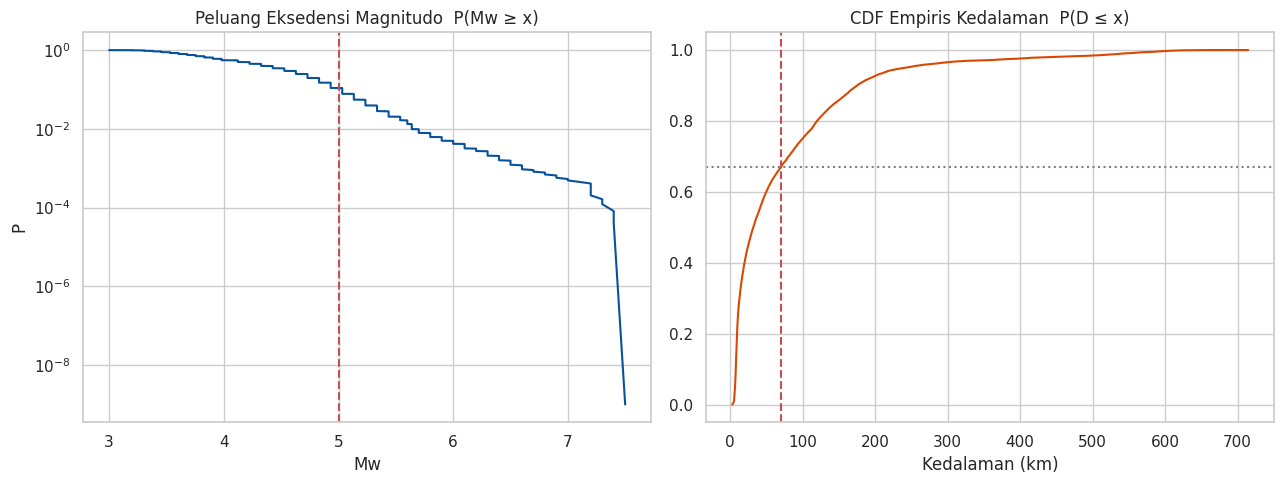

In [19]:
# 4d. Peluang kejadian dalam rentang waktu (asumsi Poisson, rate dari data)
total_hari = (df["Tanggal"].max() - df["Tanggal"].min()).days + 1
print("\n--- Peluang minimal 1 kejadian dalam periode waktu (model Poisson) ---")
print(f"Rentang data: {total_hari} hari ({total_hari/365.25:.2f} tahun)")
syarat = {"Mw >= 5": mag >= 5, "Mw >= 6": mag >= 6, "Mw >= 7": mag >= 7,
          "D < 70 km": dep < 70, "Mw >= 5 & D < 70": (mag >= 5) & (dep < 70)}
tab_pois = []
for nm, m in syarat.items():
    n_ev = int(m.sum())
    lam_hari = n_ev / total_hari
    row = {"Kriteria": nm, "N": n_ev, "Rate/hari": lam_hari, "Rate/tahun": lam_hari * 365.25}
    for lab, h in [("1 hari", 1), ("1 minggu", 7), ("1 bulan", 30.4375), ("1 tahun", 365.25)]:
        row[f"P(>=1) {lab}"] = 1 - np.exp(-lam_hari * h)
    tab_pois.append(row)
tab_pois = pd.DataFrame(tab_pois)
print(tab_pois.round(4).to_string(index=False))
tab_pois.round(5).to_csv(os.path.join(OUT_DIR, "04_peluang_poisson.csv"), index=False)

# Periode ulang (return period)
print("\nPeriode ulang rata-rata (hari antar-kejadian):")
for nm, m in syarat.items():
    if m.sum():
        print(f"  {nm:20s}: {total_hari / m.sum():.2f} hari")

# Visualisasi peluang eksedensi
N_total = len(df)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
xs = np.sort(mag)
ax[0].plot(xs, 1 - np.arange(1, N_total + 1) / N_total + 1e-9, color="#08519c")
ax[0].set_yscale("log"); ax[0].axvline(5, ls="--", c="r")
ax[0].set_title("Peluang Eksedensi Magnitudo  P(Mw ≥ x)"); ax[0].set_xlabel("Mw"); ax[0].set_ylabel("P")
xd = np.sort(dep)
ax[1].plot(xd, np.arange(1, N_total + 1) / N_total, color="#d94801")
ax[1].axvline(70, ls="--", c="r"); ax[1].axhline(p_d70, ls=":", c="gray")
ax[1].set_title("CDF Empiris Kedalaman  P(D ≤ x)"); ax[1].set_xlabel("Kedalaman (km)")
simpan("04_peluang_eksedensi.png")

## 5. HUBUNGAN KEDALAMAN DAN MAGNITUDO

Pearson  r   = 0.1777  (p=6.95e-173)
Spearman rho = 0.2162  (p=7.49e-257)
Kendall  tau = 0.1442  (p=1.93e-241)
Pearson (ln Kedalaman vs Mw) = 0.2147  (p=2.38e-253)
IK 95% Pearson (Fisher-z): [0.1656, 0.1898]

Regresi linear: Mw = 4.1334 + 0.001097 * Kedalaman
R^2 = 0.0316, p(slope)=6.95e-173, SE(slope)=3.88e-05
Regresi log: Mw = 3.8322 + 0.1071 * ln(Kedalaman), R^2 = 0.0461

Ringkasan magnitudo per kelas kedalaman (BMKG):
                   count   mean  median    std    min  max
Kelas_Kedalaman                                           
Dangkal (<60)      15646  4.140   3.980  0.607  3.000  7.5
Menengah (60-300)   7998  4.316   4.325  0.588  3.307  7.3
Dalam (>300)         841  4.571   4.527  0.506  3.382  7.4
Kruskal-Wallis: H=819.71, p=1.01e-178
ANOVA satu arah: F=385.22, p=1.9e-165
Ukuran efek (epsilon^2 Kruskal-Wallis) ≈ 0.0334

Mw dangkal (<70): mean=4.150 (n=16394), Mw non-dangkal (>=70): mean=4.339 (n=8091)
Welch t-test: t=-23.574, p=6.17e-121 | Mann-Whitney U: p=7.77e-133
Cohe

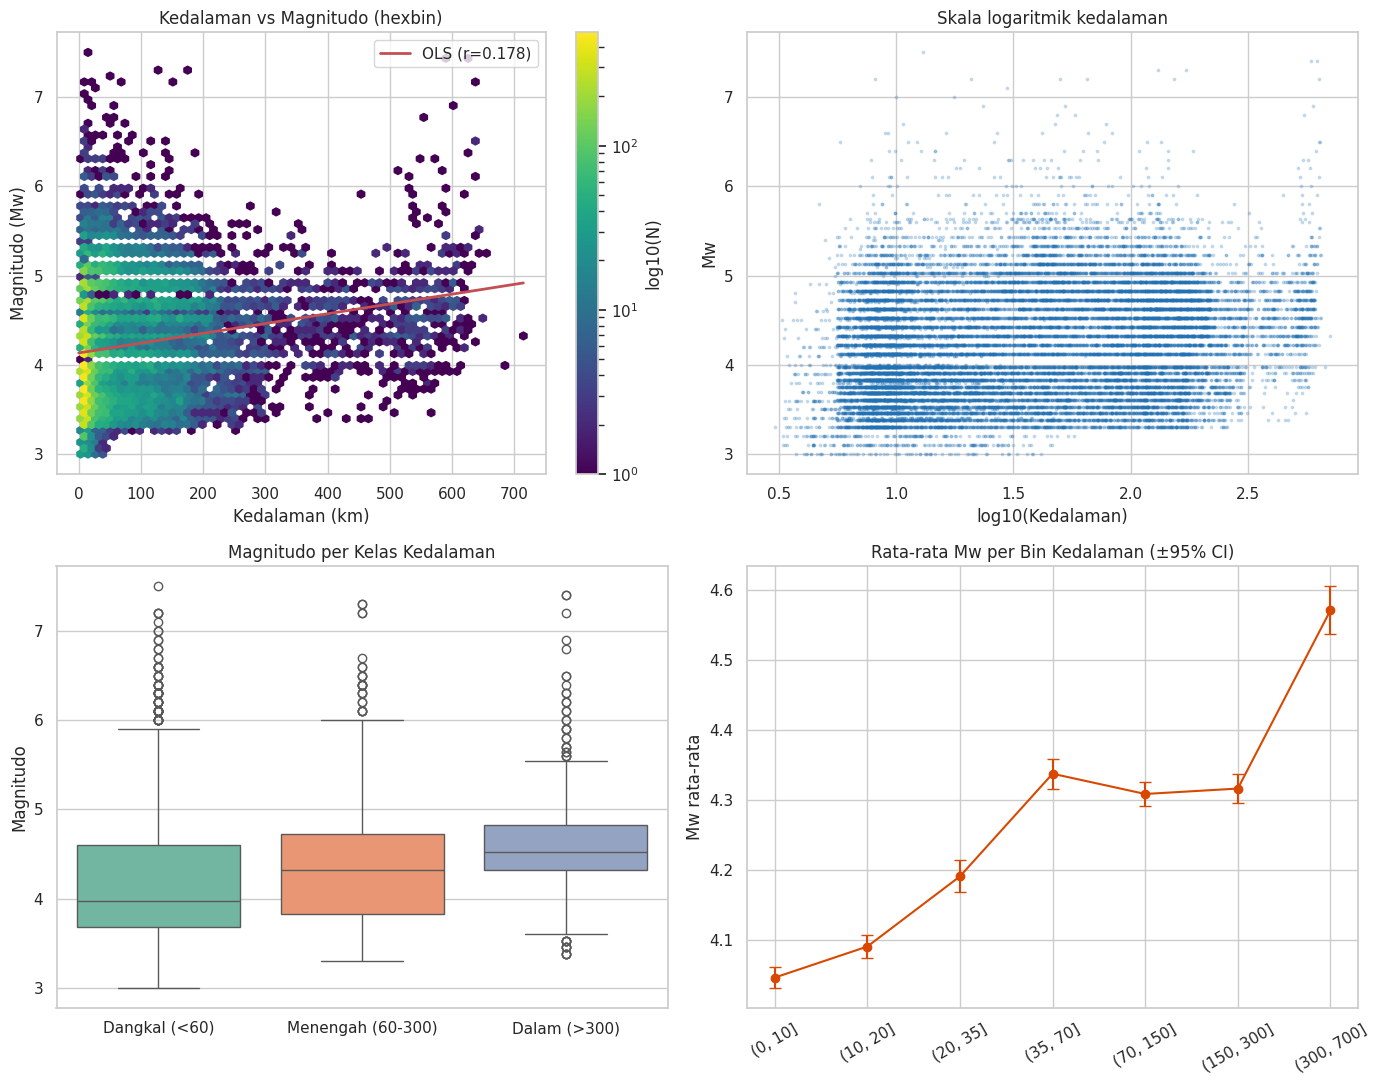

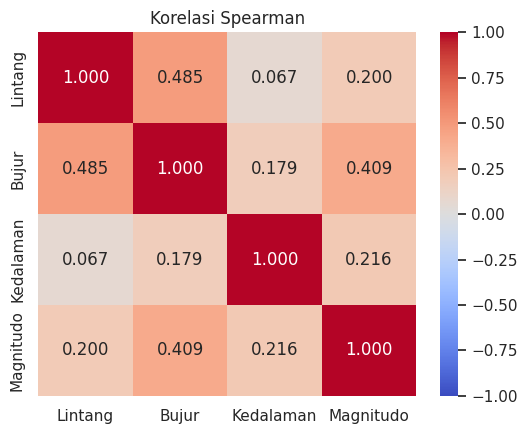

In [22]:
N = len(df)
pear = stats.pearsonr(dep, mag)
spear = stats.spearmanr(dep, mag)
kend = stats.kendalltau(dep, mag)
print(f"Pearson  r   = {pear.statistic:.4f}  (p={pear.pvalue:.3g})")
print(f"Spearman rho = {spear.statistic:.4f}  (p={spear.pvalue:.3g})")
print(f"Kendall  tau = {kend.statistic:.4f}  (p={kend.pvalue:.3g})")

# Pearson dengan log-kedalaman
pear_log = stats.pearsonr(np.log(dep), mag)
print(f"Pearson (ln Kedalaman vs Mw) = {pear_log.statistic:.4f}  (p={pear_log.pvalue:.3g})")

# Interval kepercayaan Fisher-z
def ci_fisher(r, n, z=1.96):
    zr = np.arctanh(r); se = 1 / np.sqrt(n - 3)
    return np.tanh(zr - z * se), np.tanh(zr + z * se)

lo, hi = ci_fisher(pear.statistic, N)
print(f"IK 95% Pearson (Fisher-z): [{lo:.4f}, {hi:.4f}]")

# Regresi linear sederhana: Mw = a + b * Kedalaman
reg = stats.linregress(dep, mag)
print(f"\nRegresi linear: Mw = {reg.intercept:.4f} + {reg.slope:.6f} * Kedalaman")
print(f"R^2 = {reg.rvalue ** 2:.4f}, p(slope)={reg.pvalue:.3g}, SE(slope)={reg.stderr:.2e}")
reg_log = stats.linregress(np.log(dep), mag)
print(f"Regresi log: Mw = {reg_log.intercept:.4f} + {reg_log.slope:.4f} * ln(Kedalaman), R^2 = {reg_log.rvalue ** 2:.4f}")

# Perbandingan antar kelas kedalaman
print("\nRingkasan magnitudo per kelas kedalaman (BMKG):")
rk = df.groupby("Kelas_Kedalaman")["Magnitudo"].agg(["count", "mean", "median", "std", "min", "max"])
print(rk.round(3))
rk.round(4).to_csv(os.path.join(OUT_DIR, "05_magnitudo_per_kelas_kedalaman.csv"))
grup = [g["Magnitudo"].values for _, g in df.groupby("Kelas_Kedalaman") if len(g) > 1]
kw = stats.kruskal(*grup)
an = stats.f_oneway(*grup)
print(f"Kruskal-Wallis: H={kw.statistic:.2f}, p={kw.pvalue:.3g}")
print(f"ANOVA satu arah: F={an.statistic:.2f}, p={an.pvalue:.3g}")
eta2 = (kw.statistic - len(grup) + 1) / (N - len(grup))
print(f"Ukuran efek (epsilon^2 Kruskal-Wallis) ≈ {eta2:.4f}")

# Dangkal vs non-dangkal (batas 70 km)
a = df.loc[dep < 70, "Magnitudo"]; c = df.loc[dep >= 70, "Magnitudo"]
mw = stats.mannwhitneyu(a, c, alternative="two-sided")
tt = stats.ttest_ind(a, c, equal_var=False)
print(f"\nMw dangkal (<70): mean={a.mean():.3f} (n={len(a)}), Mw non-dangkal (>=70): mean={c.mean():.3f} (n={len(c)})")
print(f"Welch t-test: t={tt.statistic:.3f}, p={tt.pvalue:.3g} | Mann-Whitney U: p={mw.pvalue:.3g}")
d_cohen = (a.mean() - c.mean()) / np.sqrt(((len(a) - 1) * a.var() + (len(c) - 1) * c.var()) / (len(a) + len(c) - 2))
print(f"Cohen's d = {d_cohen:.3f}")

# Rata-rata magnitudo per bin kedalaman
bins_d = [0, 10, 20, 35, 70, 150, 300, 700]
df["Bin_D"] = pd.cut(df["Kedalaman"], bins_d)
rb = df.groupby("Bin_D")["Magnitudo"].agg(["count", "mean", "median", "std"])
rb["SE"] = rb["std"] / np.sqrt(rb["count"])
print("\nMagnitudo rata-rata per bin kedalaman:")
print(rb.round(3))

# Plot hubungan
fig, ax = plt.subplots(2, 2, figsize=(14, 11))
hb = ax[0, 0].hexbin(dep, mag, gridsize=60, cmap="viridis", bins="log", mincnt=1)
plt.colorbar(hb, ax=ax[0, 0], label="log10(N)")
xs = np.linspace(0, dep.max(), 100)
ax[0, 0].plot(xs, reg.intercept + reg.slope * xs, "r-", lw=2, label=f"OLS (r={pear.statistic:.3f})")
ax[0, 0].set_xlabel("Kedalaman (km)"); ax[0, 0].set_ylabel("Magnitudo (Mw)"); ax[0, 0].legend()
ax[0, 0].set_title("Kedalaman vs Magnitudo (hexbin)")

ax[0, 1].scatter(np.log10(dep), mag, s=3, alpha=0.2, color="#2171b5")
ax[0, 1].set_xlabel("log10(Kedalaman)"); ax[0, 1].set_ylabel("Mw"); ax[0, 1].set_title("Skala logaritmik kedalaman")

sns.boxplot(data=df, x="Kelas_Kedalaman", y="Magnitudo", ax=ax[1, 0], palette="Set2")
ax[1, 0].set_title("Magnitudo per Kelas Kedalaman"); ax[1, 0].set_xlabel("")

ax[1, 1].errorbar(range(len(rb)), rb["mean"], yerr=1.96 * rb["SE"], fmt="o-", capsize=4, color="#d94801")
ax[1, 1].set_xticks(range(len(rb))); ax[1, 1].set_xticklabels([str(i) for i in rb.index], rotation=30)
ax[1, 1].set_title("Rata-rata Mw per Bin Kedalaman (±95% CI)"); ax[1, 1].set_ylabel("Mw rata-rata")
simpan("05_hubungan_kedalaman_magnitudo.png")

# Heatmap korelasi
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(df[["Lintang", "Bujur", "Kedalaman", "Magnitudo"]].corr(method="spearman"),
            annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Korelasi Spearman")
simpan("05_heatmap_korelasi.png")